### РОССИЙСКИЙ УНИВЕРСИТЕТ ДРУЖБЫ НАРОДОВ
### Факультет искусственного интеллекта
### Дисциплина: Инструменты обработки и визуализации данных
## ОТЧЕТ ПО ЛАБОРАТОРНОЙ РАБОТЕ № 4
#### Студент:  Князев Арсений Михайлович
#### Группа:   ЗФИбд-01-24
#### Вариант № 1

In [1]:
import os
import sys

from pyspark.sql import SparkSession

os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ.setdefault("SPARK_LOCAL_IP", "127.0.0.1")

spark = (
    SparkSession.builder.master("local[*]")
    .appName("AdultFeaturesLab4")
    .config("spark.ui.showConsoleProgress", "false")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")

print("spark:", spark.version)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/09 16:59:17 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


spark: 4.0.1


Этап 1 - смотрим структуру данных и распределения.

Этап 2 - создаём новые признаки и собираем Pipeline.

Этап 3 - сравниваем результат на графиках.

### Загрузка данных

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.ml import Pipeline
from pyspark.ml.feature import (
    Bucketizer,
    OneHotEncoder,
    StandardScaler,
    StringIndexer,
    VectorAssembler,
)
from pyspark.sql import functions as F
from pyspark.sql.types import DoubleType, IntegerType, StringType, StructField, StructType

sns.set_theme(style="whitegrid")

DATA_FILE = "adult.data"
COLUMNS = [
    "age",
    "workclass",
    "fnlwgt",
    "education",
    "education_num",
    "marital_status",
    "occupation",
    "relationship",
    "race",
    "sex",
    "capital_gain",
    "capital_loss",
    "hours_per_week",
    "native_country",
    "income",
]

schema = StructType(
    [
        StructField("age", IntegerType(), True),
        StructField("workclass", StringType(), True),
        StructField("fnlwgt", DoubleType(), True),
        StructField("education", StringType(), True),
        StructField("education_num", IntegerType(), True),
        StructField("marital_status", StringType(), True),
        StructField("occupation", StringType(), True),
        StructField("relationship", StringType(), True),
        StructField("race", StringType(), True),
        StructField("sex", StringType(), True),
        StructField("capital_gain", DoubleType(), True),
        StructField("capital_loss", DoubleType(), True),
        StructField("hours_per_week", DoubleType(), True),
        StructField("native_country", StringType(), True),
        StructField("income", StringType(), True),
    ]
)

df_raw = (
    spark.read.option("header", False)
    .option("nullValue", "?")
    .option("ignoreLeadingWhiteSpace", True)
    .option("ignoreTrailingWhiteSpace", True)
    .schema(schema)
    .csv(DATA_FILE)
)

df = df_raw.dropna().dropDuplicates()

print("исходная форма:", (df_raw.count(), len(df_raw.columns)))
print("после очистки:", (df.count(), len(df.columns)))
df.printSchema()
print(df.dtypes)
df.show(5, truncate=False)

исходная форма: (32561, 15)


после очистки: (30139, 15)
root
 |-- age: integer (nullable = true)
 |-- workclass: string (nullable = true)
 |-- fnlwgt: double (nullable = true)
 |-- education: string (nullable = true)
 |-- education_num: integer (nullable = true)
 |-- marital_status: string (nullable = true)
 |-- occupation: string (nullable = true)
 |-- relationship: string (nullable = true)
 |-- race: string (nullable = true)
 |-- sex: string (nullable = true)
 |-- capital_gain: double (nullable = true)
 |-- capital_loss: double (nullable = true)
 |-- hours_per_week: double (nullable = true)
 |-- native_country: string (nullable = true)
 |-- income: string (nullable = true)

[('age', 'int'), ('workclass', 'string'), ('fnlwgt', 'double'), ('education', 'string'), ('education_num', 'int'), ('marital_status', 'string'), ('occupation', 'string'), ('relationship', 'string'), ('race', 'string'), ('sex', 'string'), ('capital_gain', 'double'), ('capital_loss', 'double'), ('hours_per_week', 'double'), ('native_country', '

+---+---------+--------+------------+-------------+---------------------+-----------------+-------------+-----+------+------------+------------+--------------+--------------+------+
|age|workclass|fnlwgt  |education   |education_num|marital_status       |occupation       |relationship |race |sex   |capital_gain|capital_loss|hours_per_week|native_country|income|
+---+---------+--------+------------+-------------+---------------------+-----------------+-------------+-----+------+------------+------------+--------------+--------------+------+
|42 |Private  |116632.0|Doctorate   |16           |Married-civ-spouse   |Prof-specialty   |Husband      |White|Male  |0.0         |0.0         |45.0          |United-States |>50K  |
|44 |Private  |343591.0|HS-grad     |9            |Divorced             |Craft-repair     |Not-in-family|White|Female|14344.0     |0.0         |40.0          |United-States |>50K  |
|46 |Local-gov|329752.0|11th        |7            |Married-civ-spouse   |Transport-moving 

### Корреляции и выбросы

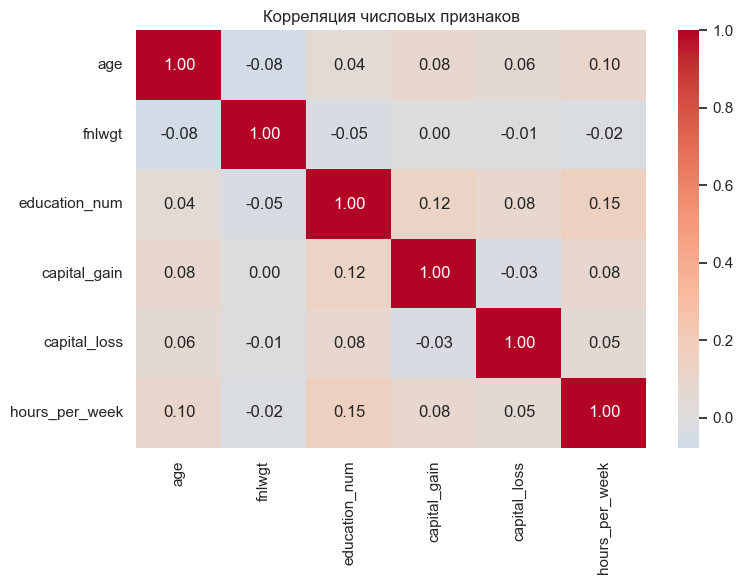

In [3]:
numeric_columns = [
    "age",
    "fnlwgt",
    "education_num",
    "capital_gain",
    "capital_loss",
    "hours_per_week",
]

numeric_pdf = df.select(numeric_columns).toPandas()
correlation = numeric_pdf.corr(method="pearson")

plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Корреляция числовых признаков")
plt.tight_layout()
plt.show()

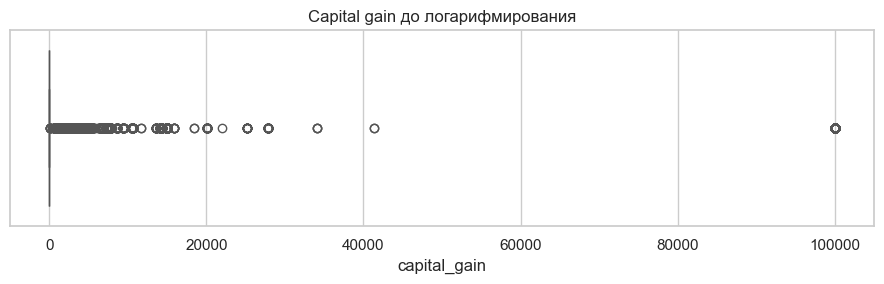

In [4]:
plt.figure(figsize=(9, 3))
sns.boxplot(x=numeric_pdf["capital_gain"], color="#72a98f")
plt.title("Capital gain до логарифмирования")
plt.xlabel("capital_gain")
plt.tight_layout()
plt.show()

### Новые признаки

In [5]:
engineered = df.withColumn(
    "capital_balance", F.col("capital_gain") - F.col("capital_loss")
).withColumn("capital_gain_log", F.log(F.col("capital_gain") + F.lit(1.0)))

age_bucketizer = Bucketizer(
    splits=[-float("inf"), 26.0, 36.0, 46.0, 61.0, float("inf")],
    inputCol="age",
    outputCol="age_bin",
    handleInvalid="keep",
)
engineered = age_bucketizer.transform(engineered)

engineered = engineered.withColumn(
    "age_group",
    F.when(F.col("age_bin") == 0, "17-25")
    .when(F.col("age_bin") == 1, "26-35")
    .when(F.col("age_bin") == 2, "36-45")
    .when(F.col("age_bin") == 3, "46-60")
    .otherwise("60+"),
)

engineered.select(
    "age", "age_group", "capital_gain", "capital_loss", "capital_balance", "capital_gain_log"
).show(10)

+---+---------+------------+------------+---------------+-----------------+
|age|age_group|capital_gain|capital_loss|capital_balance| capital_gain_log|
+---+---------+------------+------------+---------------+-----------------+
| 42|    36-45|         0.0|         0.0|            0.0|              0.0|
| 44|    36-45|     14344.0|         0.0|        14344.0|9.571156728415465|
| 46|    46-60|         0.0|         0.0|            0.0|              0.0|
| 29|    26-35|         0.0|         0.0|            0.0|              0.0|
| 47|    46-60|         0.0|         0.0|            0.0|              0.0|
| 20|    17-25|         0.0|         0.0|            0.0|              0.0|
| 23|    17-25|         0.0|         0.0|            0.0|              0.0|
| 24|    17-25|         0.0|         0.0|            0.0|              0.0|
| 55|    46-60|         0.0|         0.0|            0.0|              0.0|
| 55|    46-60|         0.0|         0.0|            0.0|              0.0|
+---+-------

In [6]:
top_countries = [
    row["native_country"]
    for row in (
        engineered.groupBy("native_country").count().orderBy(F.desc("count")).limit(5).collect()
    )
]

engineered = engineered.withColumn(
    "country_group",
    F.when(F.col("native_country").isin(top_countries), F.col("native_country")).otherwise("Other"),
)

print("топ-5 стран:", top_countries)
country_counts = engineered.groupBy("country_group").count().orderBy(F.desc("count"))
country_counts.show()

топ-5 стран: ['United-States', 'Mexico', 'Philippines', 'Germany', 'Puerto-Rico']


+-------------+-----+
|country_group|count|
+-------------+-----+
|United-States|27487|
|        Other| 1621|
|       Mexico|  606|
|  Philippines|  188|
|      Germany|  128|
|  Puerto-Rico|  109|
+-------------+-----+



### Pipeline

In [7]:
sex_indexer = StringIndexer(inputCol="sex", outputCol="sex_index", handleInvalid="keep")
sex_ohe = OneHotEncoder(inputCol="sex_index", outputCol="sex_ohe")
occupation_indexer = StringIndexer(
    inputCol="occupation", outputCol="occupation_index", handleInvalid="keep"
)

numeric_assembler = VectorAssembler(
    inputCols=["hours_per_week", "capital_balance", "capital_gain_log"],
    outputCol="numeric_features",
)
scaler = StandardScaler(
    inputCol="numeric_features",
    outputCol="scaled_features",
    withMean=True,
    withStd=True,
)

pipeline = Pipeline(stages=[sex_indexer, sex_ohe, occupation_indexer, numeric_assembler, scaler])
pipeline_model = pipeline.fit(engineered)
transformed = pipeline_model.transform(engineered)

transformed.select(
    "sex",
    "sex_ohe",
    "occupation",
    "occupation_index",
    "hours_per_week",
    "scaled_features",
).show(10, truncate=False)

+------+-------------+-----------------+----------------+--------------+---------------------------------------------------------------+
|sex   |sex_ohe      |occupation       |occupation_index|hours_per_week|scaled_features                                                |
+------+-------------+-----------------+----------------+--------------+---------------------------------------------------------------+
|Male  |(2,[0],[1.0])|Prof-specialty   |0.0             |45.0          |[0.339375676953971,-0.13512447653036108,-0.3011336535141148]   |
|Female|(2,[1],[1.0])|Craft-repair     |1.0             |40.0          |[-0.07803003652729552,1.79460773442751,3.5716721516434764]     |
|Male  |(2,[0],[1.0])|Transport-moving |7.0             |30.0          |[-0.9128414634898285,-0.13512447653036108,-0.3011336535141148] |
|Male  |(2,[0],[1.0])|Adm-clerical     |3.0             |60.0          |[1.5915928173977705,-0.13512447653036108,-0.3011336535141148]  |
|Male  |(2,[0],[1.0])|Handlers-cleaners|8

### Распределения до и после логарифмирования

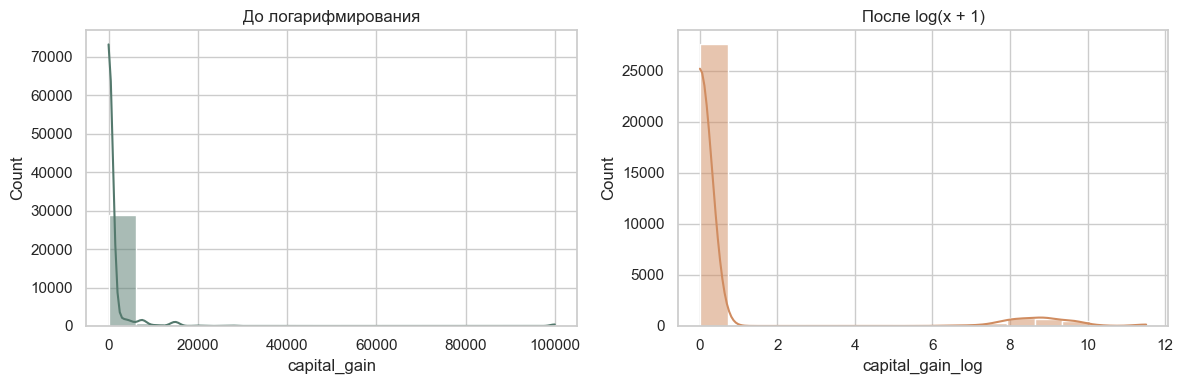

In [8]:
capital_pdf = engineered.select("capital_gain", "capital_gain_log").toPandas()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(capital_pdf["capital_gain"], kde=True, ax=axes[0], color="#54796d")
axes[0].set_title("До логарифмирования")
sns.histplot(capital_pdf["capital_gain_log"], kde=True, ax=axes[1], color="#d08c60")
axes[1].set_title("После log(x + 1)")
plt.tight_layout()
plt.show()

### Укрупнение стран

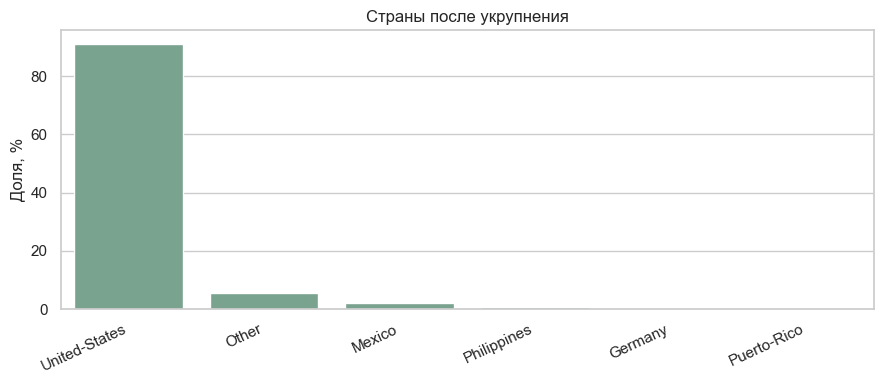

In [9]:
country_pdf = country_counts.toPandas()
country_pdf["share_pct"] = country_pdf["count"] / country_pdf["count"].sum() * 100

plt.figure(figsize=(9, 4))
sns.barplot(data=country_pdf, x="country_group", y="share_pct", color="#72a98f")
plt.title("Страны после укрупнения")
plt.xlabel("")
plt.ylabel("Доля, %")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

### Возрастные группы по полу

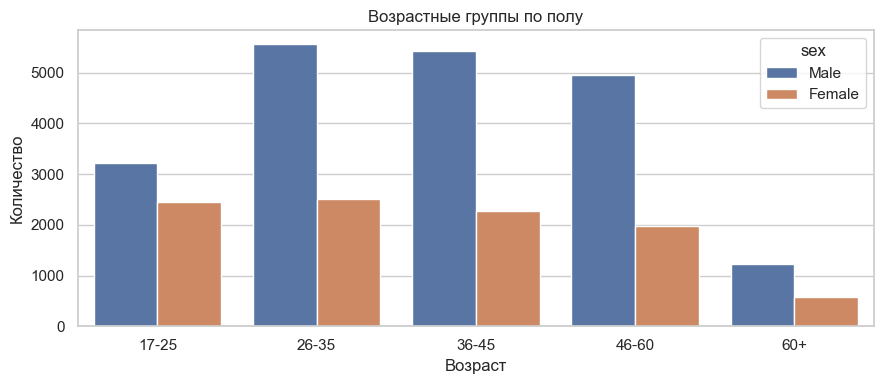

In [10]:
age_pdf = engineered.select("age_group", "sex").toPandas()
age_order = ["17-25", "26-35", "36-45", "46-60", "60+"]

plt.figure(figsize=(9, 4))
sns.countplot(data=age_pdf, x="age_group", hue="sex", order=age_order)
plt.title("Возрастные группы по полу")
plt.xlabel("Возраст")
plt.ylabel("Количество")
plt.tight_layout()
plt.show()

### Вывод

После удаления строк с `?` и дубликатов осталось 30139 записей. У `capital_gain` заметны сильная асимметрия и выбросы, поэтому для него добавлен `log(x + 1)`. Возраст разбит на пять групп, редкие страны объединены в `Other`, пол закодирован через OHE, профессия - через StringIndexer. Числовые признаки собраны и масштабированы в Pipeline.